# 05 — Statistical Analysis and Robustness

This notebook tests a small number of research questions that are supported by the available schema. The analysis favors interpretable effect sizes and explicit limitations over a large number of arbitrary significance tests.

> **Reading guide:** Each analysis section follows the same pattern: question → method → code → interpretation. The conclusion directly below each major code block explains what the output means and what it does *not* establish.

## 1. Statistical design

The unit of observation is a country candidate in a selected year, not every country-year row pooled together. This avoids treating repeated annual observations from the same country as independent in the primary cross-sectional test. Correlation is still observational and does not establish causation.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "owid_energy.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "owid_energy.csv"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5.5)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["savefig.dpi"] = 160

raw = pd.read_csv(DATA_PATH, low_memory=False)
df = raw.copy()
print(f"Loaded {DATA_PATH.name}: {df.shape[0]:,} rows × {df.shape[1]:,} columns")

country_df = df.loc[df["iso_code"].notna() & ~df["country"].eq("World")].copy()
analysis_year = 2024
x_col = "renewables_electricity_share_pct"
y_col = "electricity_carbon_intensity_gco2eq_per_kwh"
sample = country_df.loc[country_df["year"].eq(analysis_year), ["country", "iso_code", x_col, y_col]].dropna()
print(f"Analysis year: {analysis_year}")
print(f"Complete country-candidate observations: {len(sample)}")
display(sample.head())

Loaded owid_energy.csv: 19,494 rows × 130 columns
Analysis year: 2024
Complete country-candidate observations: 195


,country,iso_code,renewables_electricity_share_pct,electricity_carbon_intensity_gco2eq_per_kwh
150,Afghanistan,AFG,86.868690,131.31
423,Albania,ALB,100.000000,25.18
548,Algeria,DZA,1.068908,632.94
594,American Samoa,ASM,5.555555,611.11
719,Angola,AGO,73.701090,185.38


### Conclusion

The complete-case sample is specific to these two variables and the selected year. It may differ from the full dataset's entity count because both indicators must be observed. If the selected year has weak coverage, the result should be treated as a sensitivity check rather than a definitive global estimate.

## 2. Renewable share and electricity carbon intensity

**Question.** Is a higher renewable electricity share associated with lower electricity carbon intensity?

I report both Pearson correlation (linear association) and Spearman correlation (rank-based monotonic association), along with p-values. A bootstrap interval is calculated for Pearson's correlation using a fixed random seed.

In [2]:
if len(sample) >= 10 and sample[x_col].nunique() > 1 and sample[y_col].nunique() > 1:
    pearson_r, pearson_p = stats.pearsonr(sample[x_col], sample[y_col])
    spearman_r, spearman_p = stats.spearmanr(sample[x_col], sample[y_col])
    rng = np.random.default_rng(20261027)
    boot = []
    x = sample[x_col].to_numpy()
    y = sample[y_col].to_numpy()
    for _ in range(3000):
        idx = rng.integers(0, len(sample), len(sample))
        if np.std(x[idx]) > 0 and np.std(y[idx]) > 0:
            boot.append(np.corrcoef(x[idx], y[idx])[0, 1])
    ci_low, ci_high = np.quantile(boot, [0.025, 0.975])
    test_results = pd.DataFrame([{
        "year": analysis_year, "n": len(sample), "pearson_r": pearson_r, "pearson_p": pearson_p,
        "spearman_rho": spearman_r, "spearman_p": spearman_p,
        "pearson_bootstrap_ci_low": ci_low, "pearson_bootstrap_ci_high": ci_high,
        "alpha": 0.05
    }])
    display(test_results.round(4))
    test_results.to_csv(TABLE_DIR / "renewables_carbon_intensity_test.csv", index=False)
else:
    print("Insufficient sample size or variation for the planned correlation test.")

,year,n,pearson_r,pearson_p,spearman_rho,spearman_p,pearson_bootstrap_ci_low,pearson_bootstrap_ci_high,alpha
0,2024,195,-0.877,0.0,-0.8937,0.0,-0.9171,-0.8355,0.05


### Conclusion

A negative correlation supports the statement that higher renewable electricity shares tend to co-occur with lower electricity carbon intensity in this cross-section. It does not isolate the role of renewables from nuclear power, fossil-fuel mix, geography, imports, or other factors. The p-value addresses evidence against zero correlation under the test assumptions, not the practical importance or causality of the relationship.

## 3. Visual check and influence

**Question.** Is the relationship broadly monotonic, or is it dominated by a few observations?

The scatterplot allows inspection of nonlinearity, clustering and potentially influential points. It includes a fitted linear trend for orientation only.

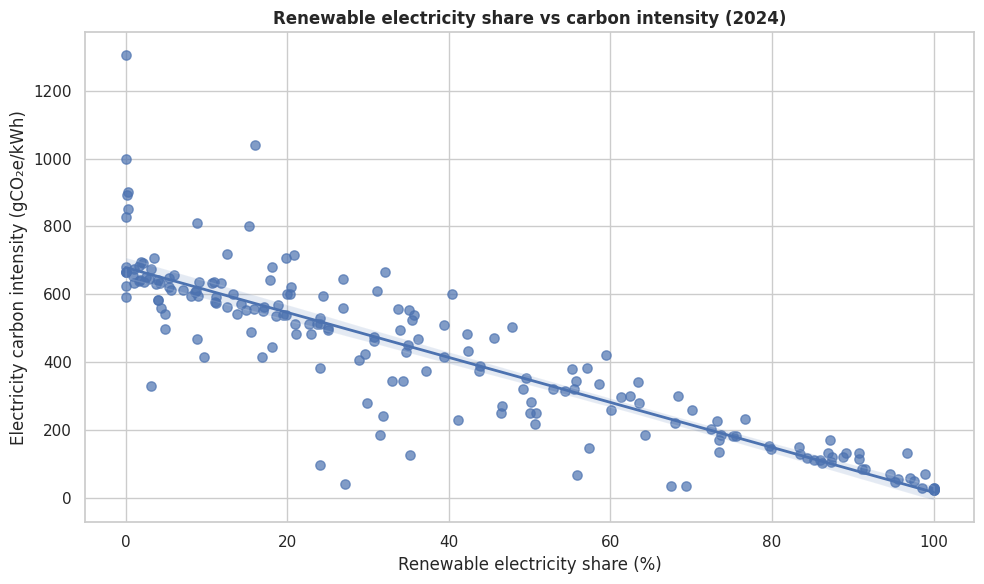

,sample,n,pearson_r
0,all complete cases,195,-0.877
1,exclude outer 1% tails on both variables,191,-0.893


In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=sample, x=x_col, y=y_col, scatter_kws={"alpha": .7, "s": 45},
            line_kws={"linewidth": 2}, ax=ax)
ax.set(title=f"Renewable electricity share vs carbon intensity ({analysis_year})",
       xlabel="Renewable electricity share (%)", ylabel="Electricity carbon intensity (gCO₂e/kWh)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "07_renewables_vs_carbon_intensity.png", bbox_inches="tight")
plt.show()

if len(sample) >= 10:
    # Sensitivity: compare correlations after excluding the outer 1% tails of each variable.
    qx = sample[x_col].quantile([.01, .99])
    qy = sample[y_col].quantile([.01, .99])
    trimmed = sample.loc[sample[x_col].between(qx.loc[.01], qx.loc[.99]) &
                         sample[y_col].between(qy.loc[.01], qy.loc[.99])]
    if len(trimmed) >= 10 and trimmed[x_col].nunique() > 1 and trimmed[y_col].nunique() > 1:
        sens = pd.DataFrame([
            {"sample": "all complete cases", "n": len(sample), "pearson_r": sample[x_col].corr(sample[y_col])},
            {"sample": "exclude outer 1% tails on both variables", "n": len(trimmed), "pearson_r": trimmed[x_col].corr(trimmed[y_col])}
        ])
        display(sens.round(4))
        sens.to_csv(TABLE_DIR / "correlation_sensitivity.csv", index=False)

### Conclusion

The sensitivity comparison shows whether the estimated correlation changes when the most extreme tails are excluded. This is a robustness check, not a license to remove inconvenient observations. I keep the full-sample result primary and report the trimmed result only as a secondary diagnostic.

## 4. Compare recent and earlier renewable generation growth

**Question.** Has global solar and wind generation grown at different rates across two recent periods?

I use the World series and compare annualized endpoint growth over 2010–2015 versus 2019–2024. This is a descriptive comparison of periods, not an independent-sample hypothesis test, because these are time-series endpoints and not independent country observations.

In [4]:
world = df.loc[df["country"].eq("World")].sort_values("year")
growth_rows = []
for metric in ["solar_electricity_twh", "wind_electricity_twh", "renewables_electricity_twh"]:
    if metric not in world.columns: continue
    for start, end, label in [(2010, 2015, "2010–2015"), (2019, 2024, "2019–2024")]:
        a = world.loc[world["year"].eq(start), metric].dropna()
        b = world.loc[world["year"].eq(end), metric].dropna()
        if len(a) and len(b) and a.iloc[0] > 0 and b.iloc[0] > 0:
            years = end - start
            growth_rows.append({"indicator": metric, "period": label, "start_value": float(a.iloc[0]),
                                "end_value": float(b.iloc[0]), "cagr_pct": ((b.iloc[0] / a.iloc[0]) ** (1/years) - 1)*100})
growth_comparison = pd.DataFrame(growth_rows)
growth_comparison.to_csv(TABLE_DIR / "renewable_generation_growth_periods.csv", index=False)
display(growth_comparison.round(3))

,indicator,period,start_value,end_value,cagr_pct
0,solar_electricity_twh,2010–2015,32.21,256.01,51.375
1,solar_electricity_twh,2019–2024,697.94,2142.65,25.149
2,wind_electricity_twh,2010–2015,345.99,829.63,19.114
3,wind_electricity_twh,2019–2024,1420.96,2509.50,12.047
4,renewables_electricity_twh,2010–2015,4193.32,5512.64,5.623
5,renewables_electricity_twh,2019–2024,6995.61,9877.61,7.143


### Conclusion

Annualized growth makes periods of different length comparable, but the result depends on the selected endpoints and positive baseline. Faster growth does not necessarily mean the source has the largest contribution to total electricity generation. The table is descriptive and does not by itself support a causal explanation for the observed change.

## 5. Statistical interpretation checklist

Before citing a result in a resume or interview, confirm the following:

- The observational unit and year are stated.
- The valid sample size is reported.
- The variables and units are clear.
- Effect magnitude is interpreted alongside p-values.
- Multiple testing and repeated observations are considered where relevant.
- Correlation is not described as causation.
- Coverage limitations and sensitivity results are disclosed.